In [1]:
# 1. LIBRERÍAS
import numpy as np
import os # sirve para interactuar con el sistema de archivos y directorios del sistema operativo
from PIL import Image # con esto importamos la librería de imágenes que sirve para abrir, manipular y guardar imágenes en diferentes formatos
import matplotlib.pyplot as plt

In [2]:
# 2. FUNCIÓN (AUTOMÁTICA POR CARPETAS)
# Esta función recorre las carpetas de un directorio, carga las imágenes, las redimensiona y normaliza, 
# y asigna etiquetas basadas en el nombre de la carpeta.
def cargar_dataset(base_dir, img_size=(150,150)):
    imagenes = []
    etiquetas = []

    for clase in os.listdir(base_dir):
        ruta_clase = os.path.join(base_dir, clase)

        if os.path.isdir(ruta_clase):
            for archivo in os.listdir(ruta_clase):
                if archivo.lower().endswith(('.jpg','.jpeg','.png')): # Verifica que el archivo sea una imagen para evitar errores  

                    ruta = os.path.join(ruta_clase, archivo)

                    img = Image.open(ruta) # Carga la imagen
                    img = img.resize(img_size) # Redimensiona la imagen al tamaño especificado
                    img = np.array(img) / 255.0 #  Normaliza los valores de píxeles a [0,1], 250 es debido a que los valores de píxeles van de 0 a 255, y al dividirlo por 255.0 se obtiene un rango de 0 a 1

                    imagenes.append(img)
                    etiquetas.append(clase)

    return np.array(imagenes), np.array(etiquetas) # finalmente guarda todas las imagenes en una lista y todas las etiquetas en otra

In [3]:
# 3. Lectura de la ruta
base_dir = r"Cars_Body_Type/train"

## Fuente del dataset y clases utilizadas

Se utiliza el dataset de Kaggle disponible en la ruta `ademboukhris/cars-body-type-cropped`, cuya página se titula **Car Body Types Images Dataset**.

[Consultar el dataset en Kaggle](https://www.kaggle.com/datasets/ademboukhris/cars-body-type-cropped)

El problema es de clasificación multiclase: a partir de una imagen de un vehículo, se busca identificar su tipo de carrocería entre siete categorías. No se utilizan los ejemplos prohibidos en el taller: MNIST, bananos verdes frente a maduros ni Fashion-MNIST.

### Imágenes cargadas para el desarrollo

Se cargan las imágenes de la carpeta `Cars_Body_Type/train`. La salida del conteo por clase registra:

| Clase | Número de imágenes |
| --- | ---: |
| Convertible | 811 |
| Coupe | 721 |
| Hatchback | 701 |
| Pick-Up | 759 |
| SUV | 847 |
| Sedan | 729 |
| VAN | 782 |
| **Total** | **5350** |

Todas las clases superan el mínimo de 200 imágenes exigido. Estas 5350 imágenes corresponden a la carpeta cargada, no al total de imágenes publicado en Kaggle. Después se dividen en entrenamiento, validación y prueba dentro del notebook.

Las etiquetas representan distintos tipos de carrocería. Sin embargo, algunas categorías pueden resultar visualmente similares según el ángulo, el recorte o el vehículo. Los errores de clasificación mostrados al final deben tenerse en cuenta al analizar esta dificultad; no basta con tener nombres de clases distintos para garantizar que todas las imágenes sean fáciles de diferenciar.

In [4]:
# 4. CARGAR DATOS
X, Y = cargar_dataset(base_dir)

print("Shape:", X.shape)
print("Ejemplo etiquetas:", Y[:10])

# Nos arroja que son 5350 imagenes, 150x 150 pixeles, y 3 canales (RGB) por ser imagenes a color

Shape: (5350, 150, 150, 3)
Ejemplo etiquetas: ['Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible'
 'Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible']


In [5]:
# Conteo de imágenes cargadas por clase
clases, conteos = np.unique(Y, return_counts=True)
for clase, conteo in zip(clases, conteos):
    print(f"{clase}: {conteo} imágenes")

print("Cumple mínimo de 200 por clase:", bool(np.all(conteos >= 200)))

Convertible: 811 imágenes
Coupe: 721 imágenes
Hatchback: 701 imágenes
Pick-Up: 759 imágenes
SUV: 847 imágenes
Sedan: 729 imágenes
VAN: 782 imágenes
Cumple mínimo de 200 por clase: True


In [6]:
# 5. CODIFICAR ETIQUETAS
# En este proceso se utiliza LabelEncoder para convertir las etiquetas de texto en números enteros, 
# lo que es necesario para el entrenamiento del modelo. Es decir, cada categoría queda con un número asignado
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

print("Clases:", labelencoder.classes_)

Clases: ['Convertible' 'Coupe' 'Hatchback' 'Pick-Up' 'SUV' 'Sedan' 'VAN']


In [7]:
# 6. SPLIT
# Aquí se divide el conjunto de datos en entrenamiento y prueba utilizando train_test_split de sklearn,
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

## Preparación de las imágenes

Para entrenar el modelo, se prepararon las imágenes mediante los siguientes pasos:

- **Carga y asignación de etiquetas:** se recorren las subcarpetas de `train` y se utiliza el nombre de cada carpeta como etiqueta. Esto permite relacionar cada imagen con su tipo de carrocería sin etiquetarla manualmente.

- **Redimensionado a 150 × 150 píxeles:** todas las imágenes se llevan al mismo tamaño para que tengan dimensiones compatibles con la entrada de la red. Este tamaño busca un equilibrio entre el detalle visual y el costo de procesamiento.

- **Normalización:** se dividen los valores de los píxeles entre 255 para pasarlos del rango de 0 a 255 al rango de 0 a 1. Esto mantiene una escala de entrada uniforme y puede facilitar la optimización durante el entrenamiento.

- **Codificación de etiquetas:** se utiliza `LabelEncoder` para convertir los nombres de las clases en etiquetas numéricas que puedan utilizarse al entrenar el modelo.

- **Separación de datos:** se realizó una única partición del conjunto de 5350 imágenes: el 80 % (4280 imágenes) se destinó al entrenamiento (`X_train`, `y_train`) y el 20 % (1070 imágenes) a las pruebas (`X_test`, `y_test`). No se realizó ninguna partición adicional ni existió un conjunto de validación. Se utilizó `random_state=42` para garantizar la reproducibilidad de la división con los mismos datos y su mismo orden.

## MODELO BASE

In [8]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout, RandomFlip, RandomRotation, RandomZoom, GlobalAveragePooling2D
import tensorflow as tf

tf.random.set_seed(3)
np.random.seed(3)

modelo = Sequential()

# Primera capa convolucional para extraer características básicas.
modelo.add(Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)))
modelo.add(MaxPooling2D(2,2))

# Convierte los mapas de características en un vector.
modelo.add(Flatten())

# Desactiva aleatoriamente algunas conexiones durante el entrenamiento.
modelo.add(Dropout(0.2))

# Capa densa para realizar la clasificación.
modelo.add(Dense(32, activation='relu'))

# Clasificación en las siete categorías.
modelo.add(Dense(7, activation='softmax'))

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = modelo.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=8
)

I0000 00:00:1793751138.296469    3159 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793751138.781032    3159 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793751141.754258    3159 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not

Epoch 1/20


I0000 00:00:1793751152.870430    4042 service.cc:153] XLA service 0x7120cc032d20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793751152.870477    4042 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793751152.904337    4042 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793751153.104328    4042 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793751153.159801    4042 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1305__.22


  3/535 ━━━━━━━━━━━━━━━━━━━━ 22s 43ms/step - accuracy: 0.0833 - loss: 10.7595     

I0000 00:00:1793751158.673565    4042 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


535/535 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.1551 - loss: 1.9962
Epoch 2/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1582 - loss: 1.9468
Epoch 3/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9444
Epoch 4/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9443
Epoch 5/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9443
Epoch 6/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9443
Epoch 7/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9443
Epoch 8/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9443
Epoch 9/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9443
Epoch 10/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9443
Epoch 11/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1584 - loss: 1.9443
Epoch 12/20
535/535 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accurac

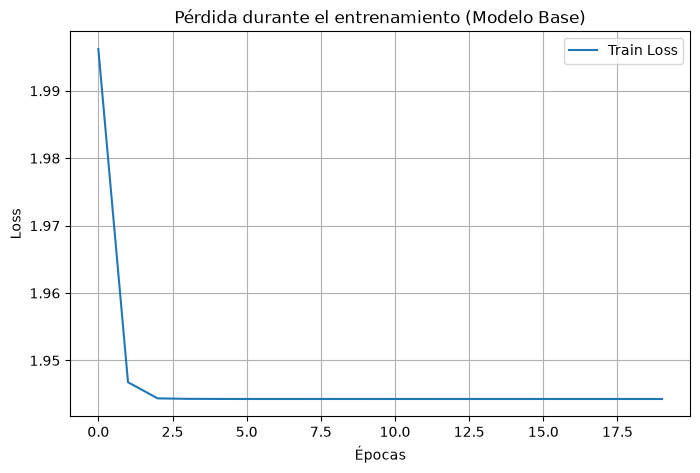

In [9]:
# Gráfica de la pérdida durante el entrenamiento del modelo base.
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

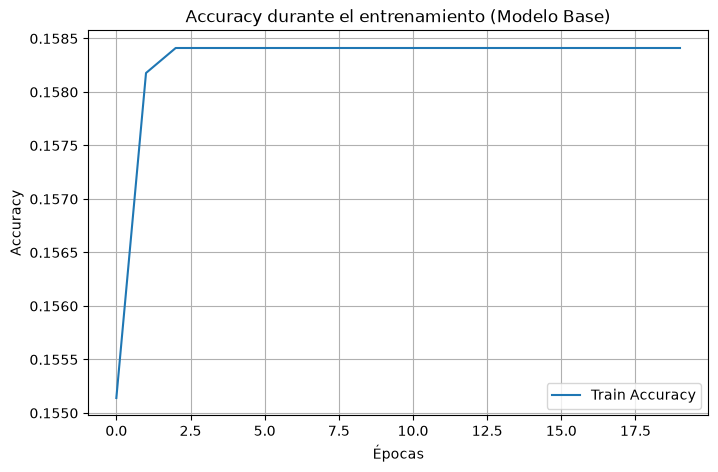

In [10]:
# Gráfica del accuracy durante el entrenamiento del modelo base.
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [11]:
# Métricas de evaluación para el modelo base utilizando accuracy_score y f1_score de sklearn.
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

134/134 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step
===== TRAIN =====
Accuracy: 0.15841121495327104
F1-score: 0.04332505193155214

===== TEST =====
Accuracy: 0.15794392523364487
F1-score: 0.04308720478528811


## Interpretación de los resultados del modelo base

Después de entrenar durante 20 épocas, la evaluación guardada en el notebook muestra estos resultados:

| Conjunto | Accuracy | F1-score ponderado |
| --- | ---: | ---: |
| Entrenamiento | 0.98569 | 0.98565 |
| Prueba | 0.57196 | 0.57962 |

El modelo clasifica correctamente aproximadamente el 98.57 % de las imágenes de entrenamiento, pero solo el 57.20 % de las imágenes de prueba. La diferencia es de aproximadamente 41.37 puntos porcentuales.

Esta diferencia indica sobreajuste: el modelo obtiene un desempeño alto con las imágenes usadas para entrenar, pero generaliza mucho peor a las imágenes de prueba. Por eso, una accuracy alta en entrenamiento no basta para afirmar que el modelo funciona bien.

El F1-score ponderado de prueba es 0.57962. Esta métrica combina la precisión y la exhaustividad de cada clase y pondera el resultado por la cantidad de ejemplos de cada clase. Se usa como complemento de la accuracy, no como un porcentaje de aciertos.

Estos resultados se toman como referencia para comparar el modelo base con el modelo optimizado.

## MODELO CNN OPTIMIZADO

In [12]:
# AUMENTO DE DATOS
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_generator = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True,
    fill_mode='nearest'
)

# CALLBACKS
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                         patience=6, min_lr=1e-5, verbose=1)
]

In [13]:
# Configuración del modelo optimizado con capas adicionales de convolución, normalización y dropout para mejorar el rendimiento.
from tensorflow.keras import layers
from tensorflow.keras import regularizers

modelo_opt = Sequential()

# Bloque 1 - 2 capas convolucionales de 32 neuronas
modelo_opt.add(Conv2D(32, (3,3), padding='same', input_shape=(150,150,3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(32, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 2 - 2 capas convolucionales de 64 neuronas
modelo_opt.add(Conv2D(64, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(64, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 3 - 2 capas convolucionales de 128 neuronas
modelo_opt.add(Conv2D(128, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(128, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 4 - 2 capas convolucionales de 256 neuronas
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))
modelo_opt.add(Dropout(0.1))   # único Dropout convolucional

# Bloque 5
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

modelo_opt.add(Flatten())   # de vuelta a Flatten: conserva información espacial

# Fully connected
modelo_opt.add(Dense(256, kernel_regularizer=regularizers.l2(0.001)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Dropout(0.5))

modelo_opt.add(Dense(128, kernel_regularizer=regularizers.l2(0.001)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Dropout(0.4))

modelo_opt.add(Dense(7, activation='softmax'))

modelo_opt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
history_opt = modelo_opt.fit(
    train_generator.flow(X_train, y_train, batch_size=32),
    validation_data=(X_test, y_test),
    epochs=90,
    callbacks=callbacks
)

Epoch 1/90


I0000 00:00:1793751253.090659    3159 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793751262.015564    4042 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_55082__.132
I0000 00:00:1793751268.849792    4042 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


 95/134 ━━━━━━━━━━━━━━━━━━━━ 4s 117ms/step - accuracy: 0.2266 - loss: 2.7841

I0000 00:00:1793751304.841154    4042 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_55082__.132


134/134 ━━━━━━━━━━━━━━━━━━━━ 93s 406ms/step - accuracy: 0.2421 - loss: 2.7419 - val_accuracy: 0.1467 - val_loss: 2.7826 - learning_rate: 0.0010
Epoch 2/90
134/134 ━━━━━━━━━━━━━━━━━━━━ 17s 123ms/step - accuracy: 0.3589 - loss: 2.3126 - val_accuracy: 0.3009 - val_loss: 2.3862 - learning_rate: 0.0010
Epoch 3/90
134/134 ━━━━━━━━━━━━━━━━━━━━ 18s 132ms/step - accuracy: 0.4528 - loss: 1.9891 - val_accuracy: 0.4551 - val_loss: 2.0194 - learning_rate: 0.0010
Epoch 4/90
134/134 ━━━━━━━━━━━━━━━━━━━━ 15s 113ms/step - accuracy: 0.5453 - loss: 1.7084 - val_accuracy: 0.5869 - val_loss: 1.5695 - learning_rate: 0.0010
Epoch 5/90
134/134 ━━━━━━━━━━━━━━━━━━━━ 16s 120ms/step - accuracy: 0.6019 - loss: 1.5185 - val_accuracy: 0.4682 - val_loss: 2.1549 - learning_rate: 0.0010
Epoch 6/90
134/134 ━━━━━━━━━━━━━━━━━━━━ 15s 115ms/step - accuracy: 0.6470 - loss: 1.3818 - val_accuracy: 0.5860 - val_loss: 1.5578 - learning_rate: 0.0010
Epoch 7/90
134/134 ━━━━━━━━━━━━━━━━━━━━ 15s 114ms/step - accuracy: 0.6645 - loss:

## Cambios implementados en el modelo optimizado

Se mantiene el esquema general de una CNN: extracción de características mediante convoluciones y pooling, aplanado con `Flatten` y clasificación mediante capas densas. El modelo optimizado amplía la arquitectura del modelo base mediante más capas convolucionales, unidades densas y técnicas de regularización.

### Aumento de datos

Se utiliza `ImageDataGenerator` para generar variaciones de las imágenes de entrenamiento: rotaciones de hasta 10 grados, zoom del 10 %, desplazamientos horizontales y verticales de hasta el 5 % y volteo horizontal aleatorio. Los espacios que aparecen al transformar las imágenes se rellenan con el modo `nearest`.

Estas transformaciones se aplican mediante `train_generator.flow(X_train, y_train, batch_size=32)` durante el entrenamiento. Buscan que el modelo aprenda con distintas posiciones y escalas de los vehículos. No se agregan fotografías originales nuevas ni se guardan automáticamente estas variaciones como archivos. El conjunto de prueba conserva las imágenes originales.

### Arquitectura y regularización

- **Convoluciones:** el modelo cuenta con nueve capas convolucionales organizadas en cinco bloques, con 32, 64, 128 y 256 filtros. Los primeros cuatro bloques tienen dos convoluciones cada uno y el quinto tiene una. Buscan aprender características visuales progresivamente más complejas.
- **Pooling:** cada bloque incluye `MaxPooling2D` para reducir las dimensiones espaciales de los mapas de características.
- **BatchNormalization:** se incorpora después de cada capa convolucional y de las dos capas densas ocultas para normalizar las activaciones y ayudar a estabilizar el entrenamiento.
- **Flatten:** convierte los mapas de características en un vector para conectarlos con las capas densas. No mantiene una estructura bidimensional explícita.
- **Capas fully connected:** se utilizan dos capas densas ocultas de 256 y 128 unidades. La salida conserva siete unidades con `softmax`, una por clase.
- **Dropout:** se aplican tasas de 0.1 después del cuarto bloque convolucional, 0.5 después de la primera capa densa y 0.4 después de la segunda. Estas desactivan aleatoriamente parte de las activaciones durante el entrenamiento para ayudar a reducir el sobreajuste.
- **Regularización L2:** las dos capas densas ocultas utilizan un factor de 0.001 para penalizar pesos grandes.

### Configuración del entrenamiento

Se utiliza Adam con una tasa de aprendizaje inicial de 0.001 y la función de pérdida `sparse_categorical_crossentropy`, compatible con las etiquetas enteras de las siete clases. El entrenamiento se configura con lotes de 32 imágenes y un máximo de 90 épocas.

Se implementan dos callbacks:

- **EarlyStopping:** supervisa `val_loss`, con una paciencia de 15 épocas y restauración de los mejores pesos.
- **ReduceLROnPlateau:** reduce a la mitad la tasa de aprendizaje cuando `val_loss` no mejora durante seis épocas, sin bajarla de 0.00001.

En este código, ambos callbacks supervisan el desempeño utilizando `X_test` y `y_test`, suministrados mediante `validation_data`.

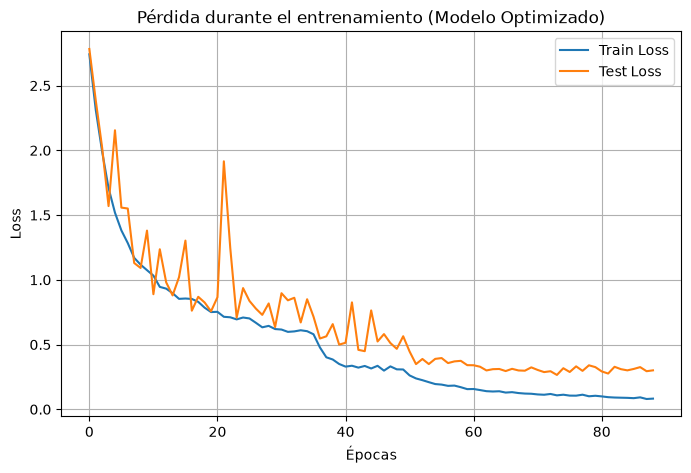

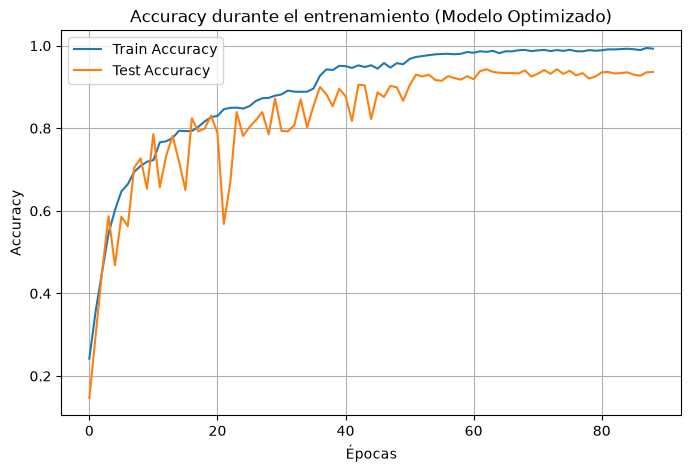

In [15]:
import matplotlib.pyplot as plt

# =========================
# LOSS (Keras registra estas métricas con el prefijo val_)
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['loss'], label='Train Loss')
plt.plot(history_opt.history['val_loss'], label='Test Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# =========================
# ACCURACY
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['accuracy'], label='Train Accuracy')
plt.plot(history_opt.history['val_accuracy'], label='Test Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [16]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo_opt.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo_opt.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

134/134 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step
===== TRAIN =====
Accuracy: 0.999766355140187
F1-score: 0.9997663539246894

===== TEST =====
Accuracy: 0.9429906542056075
F1-score: 0.9430722508104303


### Evaluación del modelo optimizado y comparación con el modelo base

Las evaluaciones guardadas muestran los siguientes resultados. En ambos modelos se utilizan los mismos conjuntos de entrenamiento y prueba.

| Modelo | Accuracy de entrenamiento | F1 ponderado de entrenamiento | Accuracy de prueba | F1 ponderado de prueba |
| --- | ---: | ---: | ---: | ---: |
| Base | 0.98569 | 0.98565 | 0.57196 | 0.57962 |
| Optimizado | 0.99977 | 0.99977 | 0.94299 | 0.94307 |

### Interpretación

El modelo optimizado clasifica correctamente aproximadamente el 94.30 % de las imágenes de prueba, frente al 57.20 % del modelo base. Esto representa una mejora de 37.10 puntos porcentuales. El F1-score ponderado de prueba también aumenta, pasando de 0.57962 a 0.94307.

La diferencia entre la accuracy de entrenamiento y la de prueba disminuye de aproximadamente 41.37 puntos porcentuales en el modelo base a 5.68 puntos en el optimizado. Esto indica una mejor generalización en esta evaluación, aunque todavía existe una diferencia entre ambos conjuntos y no se puede afirmar que el sobreajuste haya desaparecido por completo.

Las curvas del modelo optimizado permiten observar la evolución del entrenamiento y de las métricas calculadas sobre los datos de prueba. La salida registra 90 épocas completas y la restauración de los mejores pesos de la época 88, seleccionados según la menor pérdida registrada sobre los datos de prueba (`val_loss`). Por tanto, no se detuvo el entrenamiento antes de llegar al máximo de épocas configurado.

### Selección para el despliegue

Se selecciona el modelo optimizado para el despliegue local porque, entre las dos versiones evaluadas, obtiene mejores resultados de accuracy y F1-score ponderado en el mismo conjunto de prueba. El modelo seleccionado se guarda posteriormente en `modelo_cars.keras`.

La mejora corresponde al conjunto de cambios realizados: aumento de datos, mayor profundidad, normalización, regularización y ajustes del entrenamiento. Como también cambian las épocas y el tamaño del lote, esta comparación no permite atribuir la mejora a una sola capa o técnica. Los resultados corresponden a la ejecución guardada y no garantizan el mismo desempeño en cualquier imagen nueva.

In [17]:
# GUARDAR EL MODELO
modelo_opt.save("modelo_cars_v4.keras")

# GUARDAR EL LABEL ENCODER ya que el modelo solo guarda los pesos, no la información de las clases, 
# por lo que es necesario guardar el label encoder para poder interpretar las predicciones del modelo posteriormente.
import pickle

with open("labelencoder_v4.pkl", "wb") as f:
    pickle.dump(labelencoder, f)

## Despliegue local y predicción de imágenes

El despliegue se carga el modelo optimizado guardado en `modelo_cars.keras` y el codificador de etiquetas de `labelencoder.pkl`

El archivo `.keras` conserva la arquitectura y los pesos del modelo, junto con su configuración de entrenamiento y el estado del optimizador. El codificador se guarda por separado para relacionar los índices numéricos de las predicciones con los nombres de las siete clases.

### Procedimiento de predicción

1. Se recorren las subcarpetas de `Cars_Body_Type/test` para localizar archivos JPG, JPEG y PNG.
2. Cada imagen se convierte a RGB, se redimensiona a 150 × 150 píxeles y sus valores se dividen entre 255, manteniendo la escala de entrada utilizada durante el entrenamiento.
3. Se agrega la dimensión del lote para enviar una imagen al modelo.
4. Se obtiene la salida `softmax` y se selecciona la clase con el valor más alto mediante `argmax`.
5. Se recupera el nombre de la clase con `LabelEncoder` y se compara con la etiqueta deducida del nombre de la carpeta que contiene la imagen.
6. Se registran los resultados de todas las imágenes y se muestran únicamente las clasificadas incorrectamente.

### Resultados de la ejecución guardada

Se procesaron 802 imágenes: 758 se clasificaron correctamente y 44 incorrectamente. La accuracy fue de aproximadamente 94.51 %.

Este resultado corresponde a la carpeta `Cars_Body_Type/test`. No debe confundirse con el 93.18 % obtenido por el modelo optimizado sobre `X_test`, que es el conjunto de 1070 imágenes separado previamente de la carpeta `train`.

La clase con mayor proporción de errores fue Coupe, con 10 errores de 79 imágenes (12.7 %). Hatchback tuvo la mayor cantidad de errores: 11 de 99 imágenes (11.1 %). La confusión más frecuente fue Hatchback clasificado como Sedan, con siete casos. Estos resultados ayudan a localizar dificultades, pero no demuestran por sí solos sus causas.

El valor mostrado como confianza es la salida máxima de `softmax`; no garantiza que la predicción sea correcta. En los ejemplos guardados también aparecen predicciones incorrectas con valores cercanos a 1.

Cargando modelo y label encoder...
Se encontraron 802 imágenes. Procesando...

===== RESUMEN =====
Total: 802 | Aciertos: 750 | Errores: 52
Accuracy: 0.9352

Errores por clase real:
  Convertible: 5/174 errores (2.9%)
  Coupe: 13/79 errores (16.5%)
  Hatchback: 15/99 errores (15.2%)
  Pick-Up: 2/110 errores (1.8%)
  SUV: 7/125 errores (5.6%)
  Sedan: 9/109 errores (8.3%)
  VAN: 1/106 errores (0.9%)

Mostrando 52 de 52 imágenes mal clasificadas...
[Convertible] 139_jpg.rf.bfa5d350f6862fa3bd866397054625cf.jpg → Predicción: VAN (confianza 0.31)


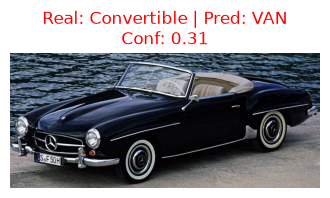

[Convertible] 193_jpg.rf.f2d23a89817ace46c43018640d51be8c.jpg → Predicción: SUV (confianza 0.54)


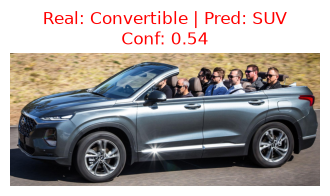

[Convertible] d8149822-66b6-11eb-b835-8c164571e025_jpg.rf.3c1bc58ef3da8aeefac898f7fc382d94.jpg → Predicción: Coupe (confianza 0.98)


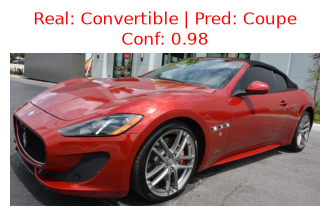

[Convertible] d8149837-66b6-11eb-b9e3-8c164571e025_jpg.rf.b29119e561c8c0b389091f0b12600e2d.jpg → Predicción: Coupe (confianza 0.73)


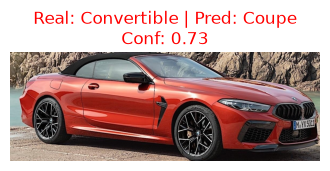

[Convertible] d814bf39-66b6-11eb-a4cb-8c164571e025_jpg.rf.d5ab471ffe435e78c827c476a1438d1f.jpg → Predicción: Coupe (confianza 0.91)


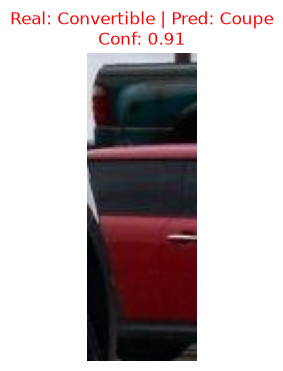

[Coupe] 00787_Infiniti-G-Coupe-IPL-2012_jpg.rf.e79fd1a3e1b7c52451090412ae574615.jpg → Predicción: Sedan (confianza 0.98)


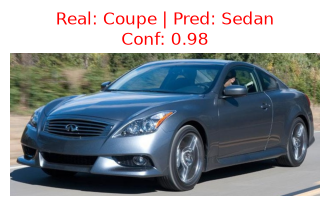

[Coupe] 04510_Aston-Martin-V8-Vantage-Coupe-2012_jpg.rf.9b6422eac00afa2c67b43a6345a6feef.jpg → Predicción: Convertible (confianza 0.97)


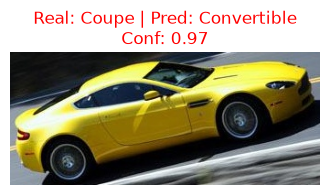

[Coupe] 06493_Honda-Accord-Coupe-2012_jpg.rf.7c2a8129792848cd89245a4e62fd4555.jpg → Predicción: Convertible (confianza 0.99)


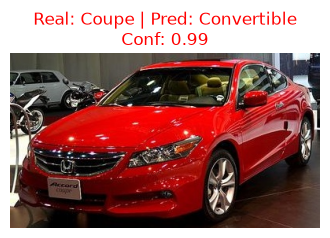

[Coupe] 06845_Audi-TTS-Coupe-2012_jpg.rf.b4ea1b949a092477d7f9d07bfe6c591c.jpg → Predicción: Convertible (confianza 0.78)


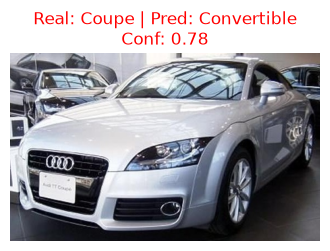

[Coupe] 0ab48d64-66b3-11eb-9141-8c164571e025_jpg.rf.8a42cb30b3b4a2f7b9e13fc793780f46.jpg → Predicción: SUV (confianza 0.94)


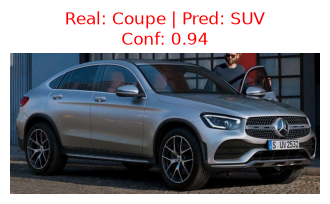

[Coupe] 0ab5c4f1-66b3-11eb-9307-8c164571e025_jpg.rf.e6eb0b5561d19cd57db65918555ec78b.jpg → Predicción: Convertible (confianza 0.45)


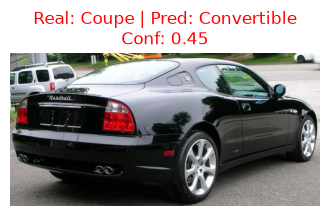

[Coupe] 148_jpg.rf.40cfaa3d6406e02d35a0f8aa54d1ff43.jpg → Predicción: Sedan (confianza 1.00)


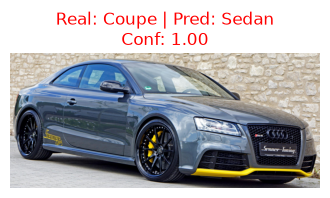

[Coupe] 171_jpg.rf.955b6ff796a4faa7a67a354d83704d52.jpg → Predicción: Convertible (confianza 0.73)


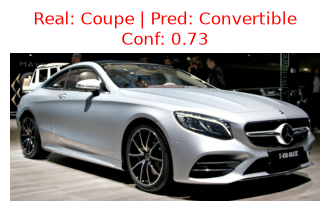

[Coupe] 172_jpg.rf.5fc9efa199832ace58289a42a4041876.jpg → Predicción: Sedan (confianza 0.91)


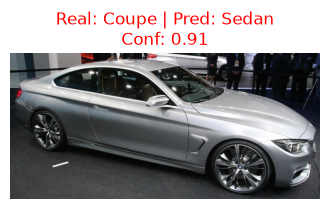

[Coupe] 173_jpg.rf.3f6d26bc2b3a933abfd57a0833704218.jpg → Predicción: Convertible (confianza 0.99)


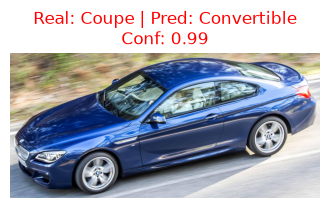

[Coupe] 313_jpg.rf.4d822638a4cf329273d6d1f53e9a649a.jpg → Predicción: Sedan (confianza 0.94)


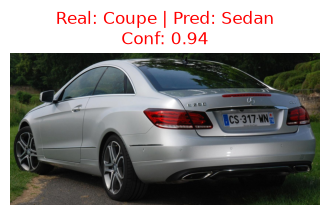

[Coupe] 77_jpg.rf.aee00019f0daef9fc545e1eae5bd81fa.jpg → Predicción: Sedan (confianza 1.00)


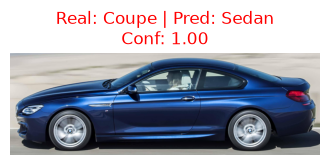

[Coupe] 80_jpg.rf.417fa09c95f9c12d09fee4cb6db4246c.jpg → Predicción: Sedan (confianza 0.99)


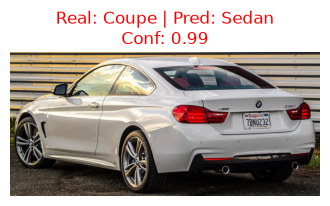

[Hatchback] 00042_Volkswagen-Golf-Hatchback-1991_jpg.rf.a9ca5d436eefa71d5842b1e825621cf7.jpg → Predicción: SUV (confianza 0.46)


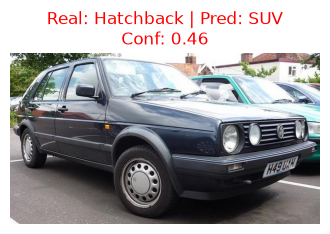

[Hatchback] 00442_Volkswagen-Golf-Hatchback-2012_jpg.rf.3875274cd997830c6fdf7d689419e48b.jpg → Predicción: Convertible (confianza 0.99)


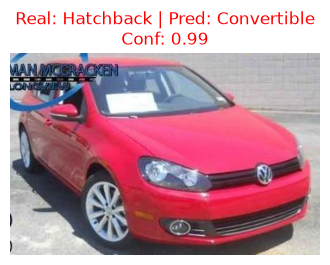

[Hatchback] 03642_Nissan-Juke-Hatchback-2012_jpg.rf.b3bce2dc909301f4d02bbe20155fe812.jpg → Predicción: SUV (confianza 0.45)


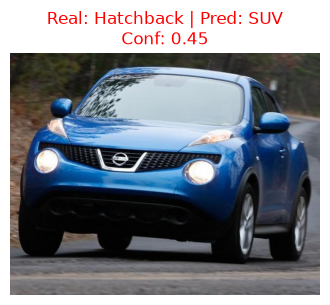

[Hatchback] 03922_Volkswagen-Golf-Hatchback-2012_jpg.rf.2e9ee3a8c1872cf6c360de7f7fa05cb9.jpg → Predicción: Sedan (confianza 0.99)


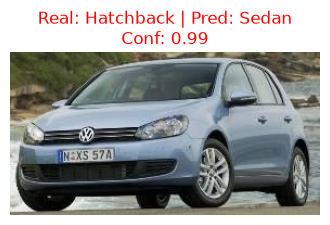

[Hatchback] 04004_Volkswagen-Golf-Hatchback-2012_jpg.rf.9c6c1c7ae0e4430a3b08657082f6c264.jpg → Predicción: SUV (confianza 0.99)


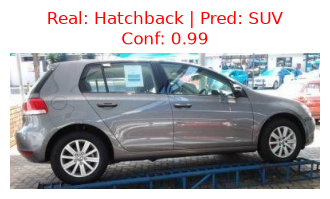

[Hatchback] 05234_Suzuki-SX4-Hatchback-2012_jpg.rf.3e82e9364278ad2a7aded40a5c5fb11f.jpg → Predicción: SUV (confianza 0.71)


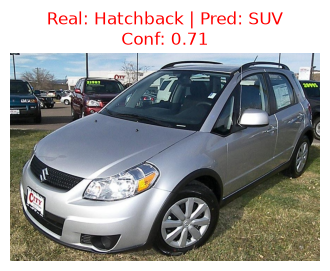

[Hatchback] 05939_Nissan-Juke-Hatchback-2012_jpg.rf.161fa5292b7c91bd3e90ca466672e382.jpg → Predicción: SUV (confianza 1.00)


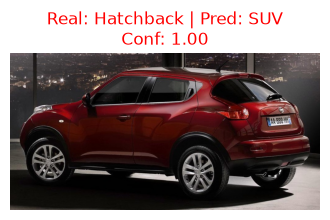

[Hatchback] d581b473-66ac-11eb-bb25-8c164571e025_jpg.rf.6cba7aece68d508854a9e09a88f236b8.jpg → Predicción: Sedan (confianza 0.87)


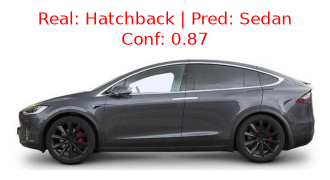

[Hatchback] d5824f90-66ac-11eb-818a-8c164571e025_jpg.rf.98b56f3dfc94f96462c142787d5c3ddd.jpg → Predicción: Sedan (confianza 1.00)


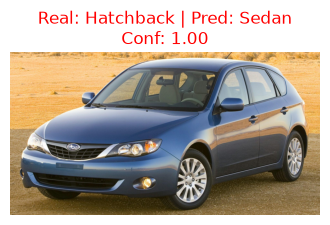

[Hatchback] d5842409-66ac-11eb-a12c-8c164571e025_jpg.rf.2f8c830e94d752e8d920ffc2dbcbe1a1.jpg → Predicción: SUV (confianza 0.56)


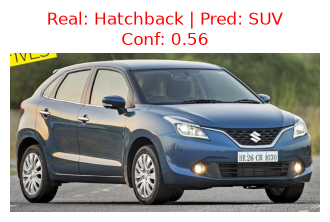

[Hatchback] d584ea22-66ac-11eb-8044-8c164571e025_jpg.rf.47945b11accee4a386875644ee7f26bf.jpg → Predicción: Sedan (confianza 0.77)


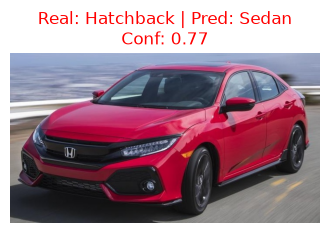

[Hatchback] d5862253-66ac-11eb-b688-8c164571e025_jpg.rf.681e1c01d13c3330dbaad5d484d97bb4.jpg → Predicción: SUV (confianza 0.62)


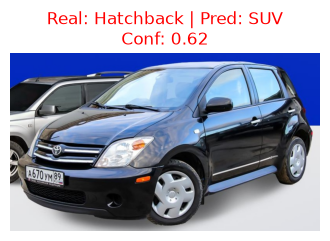

[Hatchback] d586227c-66ac-11eb-b36c-8c164571e025_jpg.rf.66f10d209c8b75a3e61fe0887fdb5087.jpg → Predicción: Sedan (confianza 0.74)


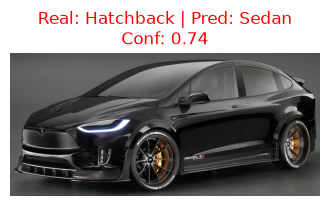

[Hatchback] d58622a9-66ac-11eb-88e3-8c164571e025_jpg.rf.6a032a17a1fd0a144c3e7f39ea7b5c38.jpg → Predicción: SUV (confianza 0.52)


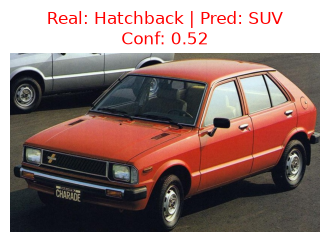

[Hatchback] Image_176_jpg.rf.cec2701b8df6969c6c772ba7332a8269.jpg → Predicción: VAN (confianza 0.96)


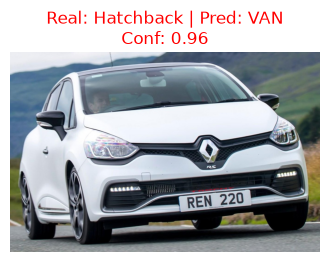

[Pick-Up] 202105062285557_jpg.rf.1d488de5eeedc9a3df13d0989dd2e831.jpg → Predicción: SUV (confianza 1.00)


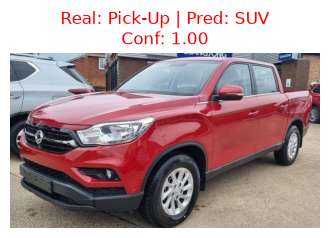

[Pick-Up] Image_137_jpg.rf.2291a2ae1c8f0c7bf466b9d9164cb4ae.jpg → Predicción: Convertible (confianza 0.63)


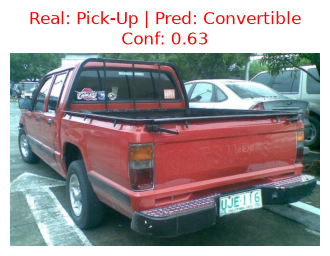

[Sedan] 01922_Suzuki-Kizashi-Sedan-2012_jpg.rf.6cdd0fa1bab29eb9ecfc909628a43a2c.jpg → Predicción: Hatchback (confianza 0.99)


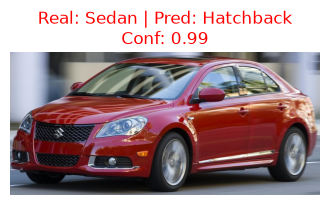

[Sedan] 07888_Mercedes-Benz-E-Class-Sedan-2012_jpg.rf.6485fad6958eee4699092f2411adb65e.jpg → Predicción: Coupe (confianza 0.73)


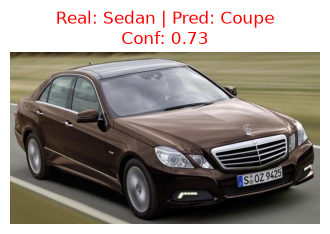

[Sedan] 392_jpg.rf.10c39b1a1164dc3fbaa8a164f16756f0.jpg → Predicción: Coupe (confianza 1.00)


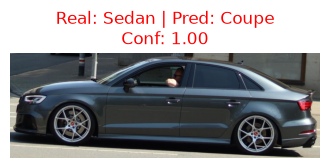

[Sedan] 44_jpg.rf.23b9e70b373e3ef5baf027fa4f0cfdc3.jpg → Predicción: Coupe (confianza 1.00)


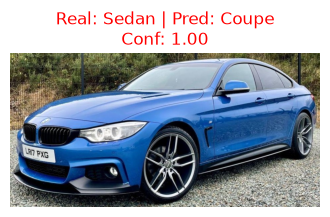

[Sedan] 466_jpg.rf.8d8a381b018b0b99d6acfb500da704fa.jpg → Predicción: Coupe (confianza 0.93)


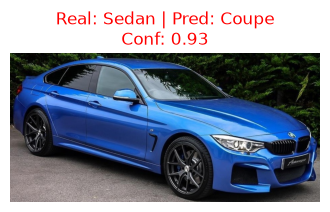

[Sedan] 7_jpg.rf.4d53b770270ca0719adeaa46805af140.jpg → Predicción: SUV (confianza 0.91)


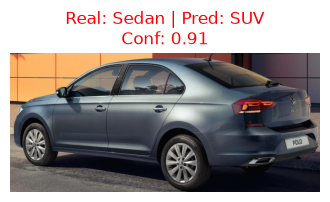

[Sedan] 8678256b-66b6-11eb-88a8-8c164571e025_jpg.rf.0d93553ac7238cfe3551702d0cf51c0d.jpg → Predicción: Hatchback (confianza 0.86)


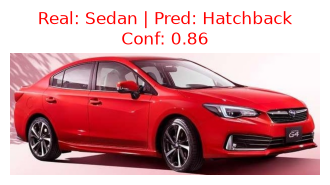

[Sedan] 867a6dbf-66b6-11eb-8bbb-8c164571e025_jpg.rf.46c576c446cd4a45b4e0da0dd0aabc3b.jpg → Predicción: Hatchback (confianza 0.91)


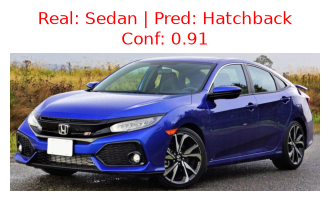

[Sedan] 91_jpg.rf.7b5e54bfbd87f407a8603b648a97cc33.jpg → Predicción: Coupe (confianza 0.81)


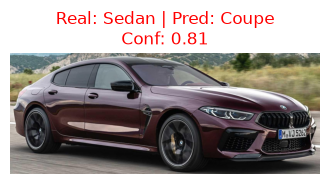

[SUV] 00409_Toyota-4Runner-SUV-2012_jpg.rf.559007d37c351113a72105daebc7a78a.jpg → Predicción: Hatchback (confianza 0.92)


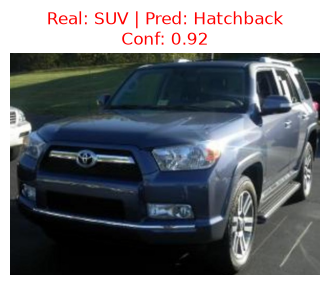

[SUV] 02690_GMC-Yukon-Hybrid-SUV-2012_jpg.rf.9c65185d0055e6eb6ba7bfd984fd30f9.jpg → Predicción: Pick-Up (confianza 0.72)


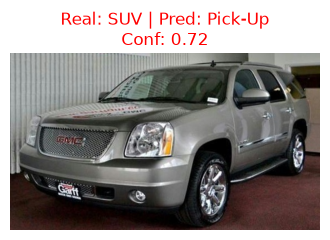

[SUV] 03837_Dodge-Journey-SUV-2012_jpg.rf.7524ece4819b9b98e7185a10749bbf1b.jpg → Predicción: Coupe (confianza 0.74)


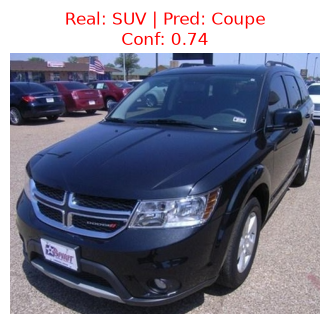

[SUV] 106_jpg.rf.3f876f0d95b54823eed10e9a5cc81a81.jpg → Predicción: Pick-Up (confianza 0.97)


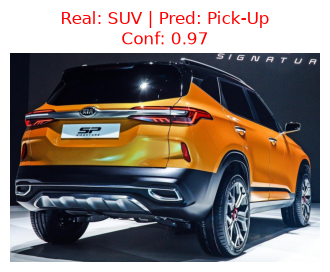

[SUV] 56_jpg.rf.047af8da56c1f75393f8e886e8fbe212.jpg → Predicción: Hatchback (confianza 0.99)


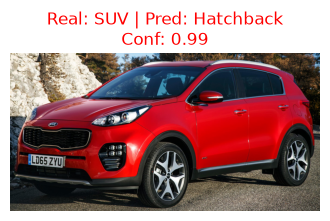

[SUV] Image_55_jpg.rf.c6c2d9dc8da8dd348038a67d14ae2255.jpg → Predicción: Pick-Up (confianza 0.86)


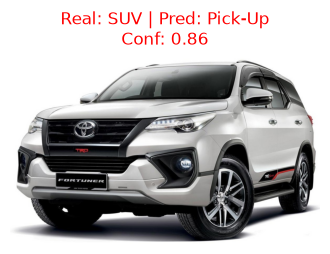

[SUV] Image_86_jpg.rf.080f77c37cb03a003c35ae2dd8257523.jpg → Predicción: Sedan (confianza 0.57)


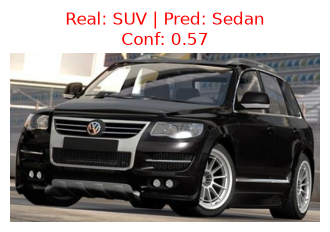

[VAN] 121_jpg.rf.66f2627045929e12e101e5b3fb59d05f.jpg → Predicción: Hatchback (confianza 0.98)


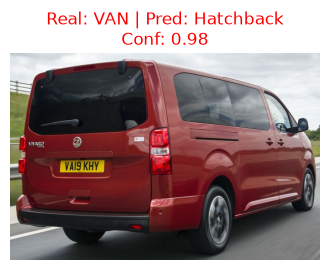

In [18]:
import os
import numpy as np
from PIL import Image
import pickle
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

# 1. Cargar modelo y label encoder
print("Cargando modelo y label encoder...")
modelo = load_model("modelo_cars_v4.keras")

with open("labelencoder_v4.pkl", "rb") as f:
    labelencoder = pickle.load(f)

# 2. Ruta de prueba
ruta_nuevos = r"Cars_Body_Type/test"
img_size = (150, 150)
EXTENSIONES = ('.jpg', '.jpeg', '.png')

# 3. Función: predice todo, pero solo muestra las incorrectas
def predecir_y_mostrar_errores(ruta_raiz, modelo, labelencoder, img_size=img_size, max_mostrar=None):
    resultados = []   # (archivo, clase_real, clase_pred, correcta)
    errores = []      # (ruta, clase_real, clase_pred)

    if not os.path.exists(ruta_raiz):
        print(f"Error: La ruta '{ruta_raiz}' no existe.")
        return resultados

    # Recolectar rutas de imágenes
    rutas = []
    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(EXTENSIONES):
                rutas.append(os.path.join(root, archivo))

    if not rutas:
        print(f"No se encontraron imágenes válidas en '{ruta_raiz}'.")
        return resultados

    print(f"Se encontraron {len(rutas)} imágenes. Procesando...")

    for ruta in rutas:
        clase_real = os.path.basename(os.path.dirname(ruta))

        # Cargar y preprocesar (convert('RGB') evita fallos con PNG/escala de grises)
        img = Image.open(ruta).convert("RGB")
        img_array = np.array(img.resize(img_size)) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        # Predicción
        pred = modelo.predict(img_array, verbose=0)
        clase_pred = labelencoder.inverse_transform(np.argmax(pred, axis=1))[0]

        correcta = str(clase_pred) == str(clase_real)
        resultados.append((os.path.basename(ruta), clase_real, clase_pred, correcta))

        if not correcta:
            errores.append((ruta, clase_real, clase_pred, float(np.max(pred))))

    # 4. Resumen general
    total = len(resultados)
    aciertos = sum(r[3] for r in resultados)
    print(f"\n===== RESUMEN =====")
    print(f"Total: {total} | Aciertos: {aciertos} | Errores: {len(errores)}")
    print(f"Accuracy: {aciertos / total:.4f}")

    # Errores por clase real
    print("\nErrores por clase real:")
    clases = sorted({r[1] for r in resultados})
    for c in clases:
        tot_c = sum(1 for r in resultados if r[1] == c)
        err_c = sum(1 for r in resultados if r[1] == c and not r[3])
        print(f"  {c}: {err_c}/{tot_c} errores ({err_c / tot_c:.1%})")

    # 5. Mostrar solo las mal clasificadas
    if not errores:
        print("\nNo hubo errores de clasificación.")
        return resultados

    a_mostrar = errores if max_mostrar is None else errores[:max_mostrar]
    print(f"\nMostrando {len(a_mostrar)} de {len(errores)} imágenes mal clasificadas...")

    for ruta, clase_real, clase_pred, confianza in a_mostrar:
        print(f"[{clase_real}] {os.path.basename(ruta)} → Predicción: {clase_pred} (confianza {confianza:.2f})")
        plt.figure(figsize=(4, 4))
        plt.imshow(Image.open(ruta).convert("RGB"))
        plt.title(f"Real: {clase_real} | Pred: {clase_pred}\nConf: {confianza:.2f}", color="red")
        plt.axis("off")
        plt.show()

    return resultados

# Ejecutar
resultados = predecir_y_mostrar_errores(ruta_nuevos, modelo, labelencoder)

Mal clasificadas: 52 de 802 (6.5%)
Bien clasificadas: 750 de 802 (93.5%)
             total  aciertos  errores  % error
real                                          
Coupe           79        66       13     16.5
Hatchback       99        84       15     15.2
Sedan          109       100        9      8.3
SUV            125       118        7      5.6
Convertible    174       169        5      2.9
Pick-Up        110       108        2      1.8
VAN            106       105        1      0.9

Confusiones más frecuentes:
real         pred       
Hatchback    SUV            8
Coupe        Convertible    6
             Sedan          6
Hatchback    Sedan          5
Sedan        Coupe          5
SUV          Pick-Up        3
Convertible  Coupe          3
Sedan        Hatchback      3
SUV          Hatchback      2
Convertible  SUV            1
Name: cantidad, dtype: int64


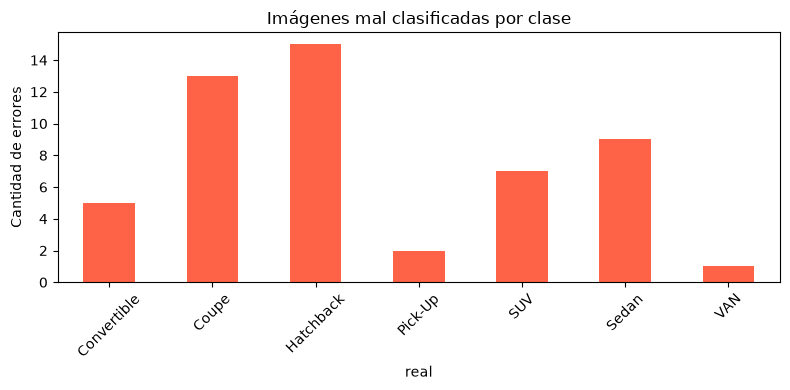

In [19]:
import pandas as pd

df = pd.DataFrame(resultados, columns=["archivo", "real", "pred", "correcta"])

total = len(df)
errores = (~df["correcta"]).sum()
print(f"Mal clasificadas: {errores} de {total} ({errores/total:.1%})")
print(f"Bien clasificadas: {total - errores} de {total} ({(total-errores)/total:.1%})")

# Errores por clase real
resumen = df.groupby("real")["correcta"].agg(
    total="count",
    aciertos="sum"
)
resumen["errores"] = resumen["total"] - resumen["aciertos"]
resumen["% error"] = (resumen["errores"] / resumen["total"] * 100).round(1)
print(resumen.sort_values("% error", ascending=False))

# Qué clases se confunden entre sí (real -> predicha)
confusiones = (
    df[~df["correcta"]]
    .groupby(["real", "pred"])
    .size()
    .sort_values(ascending=False)
    .rename("cantidad")
)
print("\nConfusiones más frecuentes:")
print(confusiones.head(10))

# Gráfico de errores por clase
resumen["errores"].plot(kind="bar", color="tomato", figsize=(8, 4))
plt.title("Imágenes mal clasificadas por clase")
plt.ylabel("Cantidad de errores")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# import os
# import numpy as np
# from PIL import Image
# import pickle
# from tensorflow.keras.models import load_model
# import matplotlib.pyplot as plt

# # 1. Cargar modelo y label encoder
# print("Cargando modelo y label encoder...")
# modelo = load_model("modelo_cars.keras")

# with open("labelencoder.pkl", "rb") as f:
#     labelencoder = pickle.load(f)

# # 2. Definir ruta de prueba
# ruta_nuevos = r"Cars_Body_Type/test"
# img_size = (150, 150)

# # 3. Función actualizada para buscar imágenes dentro de subcarpetas
# def predecir_y_mostrar_carpetas(ruta_raiz, modelo, labelencoder, img_size=img_size):
#     resultados = []
    
#     if not os.path.exists(ruta_raiz):
#         print(f"Error: La ruta '{ruta_raiz}' no existe.")
#         return resultados

#     # Usamos os.walk para recorrer la carpeta principal y todas sus subcarpetas
#     total_imagenes = 0
#     for root, dirs, files in os.walk(ruta_raiz):
#         for archivo in files:
#             if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
#                 total_imagenes += 1

#     if total_imagenes == 0:
#         print(f"No se encontraron imágenes válidas en '{ruta_raiz}' ni en sus subcarpetas.")
#         return resultados

#     print(f"Se encontraron {total_imagenes} imágenes. Procesando...")

#     for root, dirs, files in os.walk(ruta_raiz):
#         for archivo in files:
#             if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
#                 ruta = os.path.join(root, archivo)
#                 # Opcional: obtener la clase real basada en el nombre de la subcarpeta
#                 clase_real = os.path.basename(root)

#                 # Cargar y preprocesar la imagen
#                 img = Image.open(ruta)
#                 img_resized = img.resize(img_size)
                
#                 img_array = np.array(img_resized) / 255.0
#                 img_array = np.expand_dims(img_array, axis=0)

#                 # Predicción
#                 pred = modelo.predict(img_array, verbose=0)
#                 clase_pred = np.argmax(pred, axis=1)

#                 # Convertir a etiqueta original
#                 etiqueta = labelencoder.inverse_transform(clase_pred)
                
#                 resultados.append((archivo, etiqueta[0]))

#                 # Imprimir resultado en consola (mostrando la carpeta/clase real y la predicha)
#                 print(f"[{clase_real}] {archivo} → Predicción: {etiqueta[0]}")

#                 # Mostrar imagen con matplotlib
#                 plt.figure(figsize=(4, 4))
#                 plt.imshow(img)
#                 plt.title(f"Real: {clase_real} | Pred: {etiqueta[0]}")
#                 plt.axis("off")
#                 plt.show()

#     return resultados

# # Ejecutar el proceso actualizado
# resultados = predecir_y_mostrar_carpetas(ruta_nuevos, modelo, labelencoder)